In [3]:
import pandas as pd

demo = pd.read_sas('../data/DEMO_L.xpt')
bmx = pd.read_sas('../data/BMX_L.xpt')
slq = pd.read_sas('../data/SLQ_L.xpt')
paq = pd.read_sas('../data/PAQ_L.xpt')

print(f"Demographics: {demo.shape[0]} people")
print(f"Body Measures: {bmx.shape[0]} people")
print(f"Sleep Data: {slq.shape[0]} people")
print(f"Physical Activity: {paq.shape[0]} people")

df = pd.merge(demo, bmx, on='SEQN', how='inner')
df = pd.merge(df, slq, on='SEQN', how='inner')
df = pd.merge(df, paq, on='SEQN', how='inner')

initial_merged_count = len(df)
print(f"\nPeople after merging all files: {initial_merged_count}")

df = df[df['RIDAGEYR'] >= 20]
adults_count = len(df)
print(f"People dropped for being under 20: {initial_merged_count - adults_count}")

columns_to_keep = [
    'SEQN', 'RIDAGEYR', 'RIAGENDR', 'WTINT2YR', 'WTMEC2YR', 
    'BMXBMI', 'SLD013', 'PAD790Q', 'PAD810Q'
]

df = df[columns_to_keep]
df = df.dropna()
final_count = len(df)

print(f"People dropped due to missing data: {adults_count - final_count}")
print(f"Final Analytical Population: {final_count} people")

Demographics: 11933 people
Body Measures: 8860 people
Sleep Data: 8501 people
Physical Activity: 8153 people

People after merging all files: 6337
People dropped for being under 20: 273
People dropped due to missing data: 164
Final Analytical Population: 5900 people


--- Center and Spread (Continuous Variables) ---
        BMXBMI  RIDAGEYR   SLD013
count  5900.00   5900.00  5900.00
mean     29.82     53.74     8.25
std       7.35     17.15     1.70
min      11.10     20.00     2.00
25%      24.70     39.00     7.50
50%      28.50     57.00     8.00
75%      33.60     68.00     9.00
max      74.80     80.00    14.00

--- Frequency Table (Gender) ---
Gender
Female    55.29
Male      44.71
Name: proportion, dtype: float64


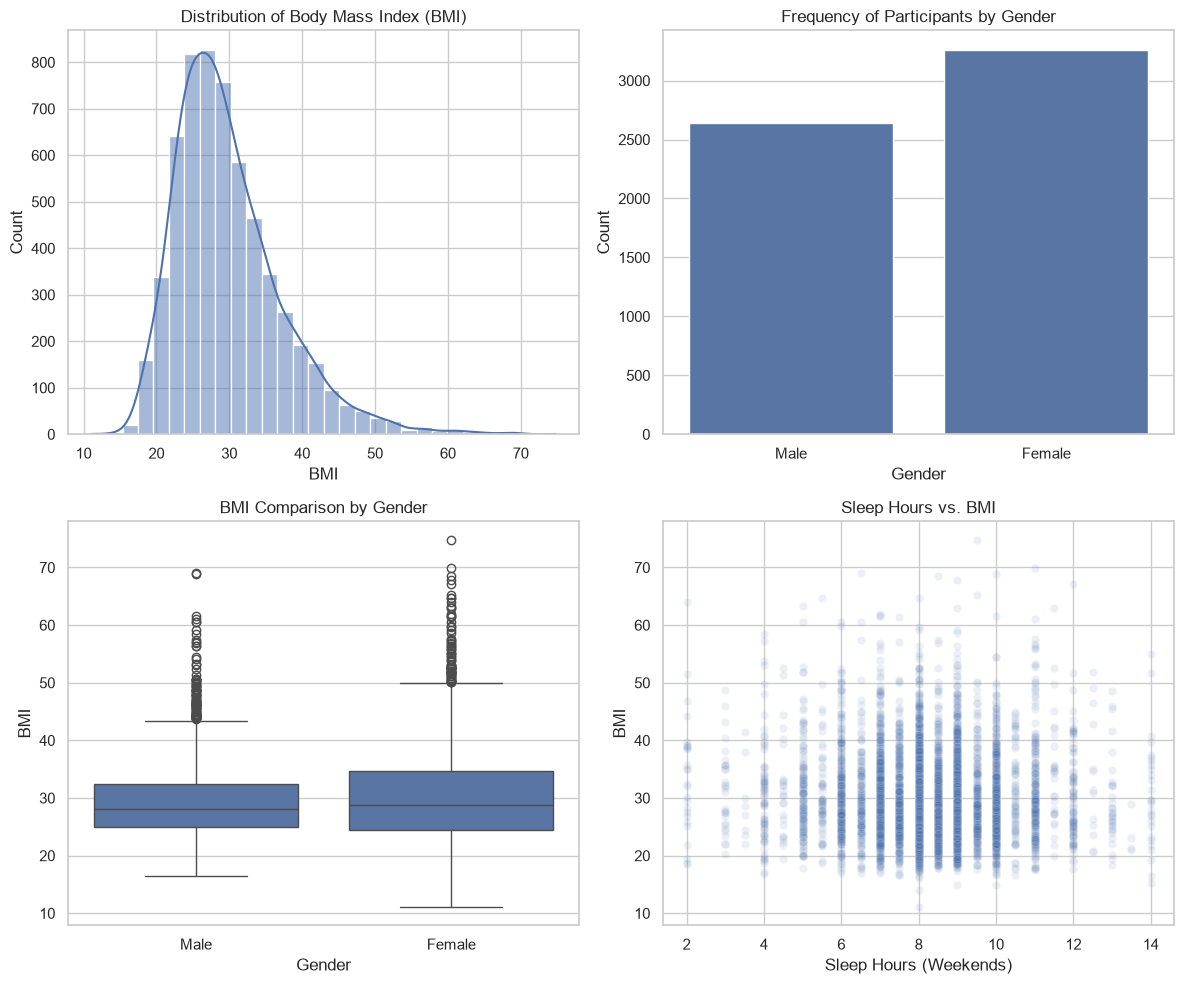

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

df['Gender'] = df['RIAGENDR'].replace({1.0: 'Male', 2.0: 'Female'})

print("--- Center and Spread (Continuous Variables) ---")
print(df[['BMXBMI', 'RIDAGEYR', 'SLD013']].describe().round(2))

print("\n--- Frequency Table (Gender) ---")
print(df['Gender'].value_counts(normalize=True).round(4) * 100)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.histplot(df['BMXBMI'], kde=True, bins=30, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Body Mass Index (BMI)')
axes[0, 0].set_xlabel('BMI')
axes[0, 0].set_ylabel('Count')

sns.countplot(x='Gender', data=df, ax=axes[0, 1])
axes[0, 1].set_title('Frequency of Participants by Gender')
axes[0, 1].set_xlabel('Gender')
axes[0, 1].set_ylabel('Count')

sns.boxplot(x='Gender', y='BMXBMI', data=df, ax=axes[1, 0])
axes[1, 0].set_title('BMI Comparison by Gender')
axes[1, 0].set_xlabel('Gender')
axes[1, 0].set_ylabel('BMI')

sns.scatterplot(x='SLD013', y='BMXBMI', data=df, alpha=0.1, ax=axes[1, 1])
axes[1, 1].set_title('Sleep Hours vs. BMI')
axes[1, 1].set_xlabel('Sleep Hours (Weekends)')
axes[1, 1].set_ylabel('BMI')

plt.tight_layout()
plt.show()